In [1]:
# Cellule 1 : Chargement du dataset (depuis ton fichier uploadé)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('adult_train.csv')
adult_test = pd.read_csv('adult_test.csv')


print("✅ Dataset chargé !")
print("TEST  :", adult_test.shape)

print(f"Lignes : {df.shape[0]} | Colonnes : {df.shape[1]}")
df.head()


✅ Dataset chargé !
TEST  : (16282, 15)
Lignes : 32561 | Colonnes : 15


,Age,Workclass,fnlwgt,Education,Education_Num,Martial_Status,Occupation,Relationship,Race,Sex,Capital_Gain,Capital_Loss,Hours_per_week,Country,Target
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


# 📊 Projet Data Science — Adult Census Income Dataset

## 1. Business Understanding

L'objectif de ce projet est d'analyser le dataset **Adult Census Income** issu de l'UCI Machine Learning Repository.

Ce dataset contient des informations socio-professionnelles sur des individus (âge, niveau d'éducation, profession, etc.) et permet de prédire si une personne gagne **plus ou moins de 50 000$ par an**.

**Problématique :** Quelles caractéristiques socio-professionnelles influencent le niveau de revenu d'un individu ?

## 2. Data Understanding


In [2]:
# Cellule 2 : Informations générales sur le dataset
print("=== TYPES DES COLONNES ===")
print(df.dtypes)
print("\n=== STATISTIQUES DESCRIPTIVES ===")
df.describe()

=== TYPES DES COLONNES ===
Age               int64
Workclass           str
fnlwgt            int64
Education           str
Education_Num     int64
Martial_Status      str
Occupation          str
Relationship        str
Race                str
Sex                 str
Capital_Gain      int64
Capital_Loss      int64
Hours_per_week    int64
Country             str
Target              str
dtype: object

=== STATISTIQUES DESCRIPTIVES ===


,Age,fnlwgt,Education_Num,Capital_Gain,Capital_Loss,Hours_per_week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [3]:
# Cellule 3 : Détection des valeurs manquantes
print("=== VALEURS MANQUANTES ===")
print(df.isnull().sum())

print("\n=== VALEURS '?' DANS LE DATASET ===")
for col in df.select_dtypes(include='object').columns:
    count = (df[col] == '?').sum()
    if count > 0:
        print(f"{col} : {count} valeurs '?'")


=== VALEURS MANQUANTES ===
Age                  0
Workclass         1836
fnlwgt               0
Education            0
Education_Num        0
Martial_Status       0
Occupation        1843
Relationship         0
Race                 0
Sex                  0
Capital_Gain         0
Capital_Loss         0
Hours_per_week       0
Country            583
Target               0
dtype: int64

=== VALEURS '?' DANS LE DATASET ===


C:\Users\utilisateur\anaconda3\tmp\ipykernel_15672\2864191074.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


Target
<=50K    24720
>50K      7841
Name: count, dtype: int64

Pourcentage <=50K : 75.9%
Pourcentage >50K  : 24.1%


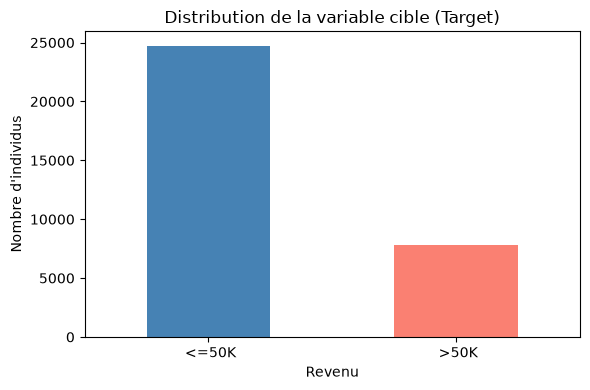

In [4]:
# Cellule 4 : Distribution de la variable cible (income/Target)
import matplotlib.pyplot as plt

counts = df['Target'].value_counts()
print(counts)
print(f"\nPourcentage <=50K : {counts.iloc[0]/len(df)*100:.1f}%")
print(f"Pourcentage >50K  : {counts.iloc[1]/len(df)*100:.1f}%")

plt.figure(figsize=(6,4))
counts.plot(kind='bar', color=['steelblue', 'salmon'])
plt.title("Distribution de la variable cible (Target)")
plt.xlabel("Revenu")
plt.ylabel("Nombre d'individus")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 3. Data Exploration & Visualisation


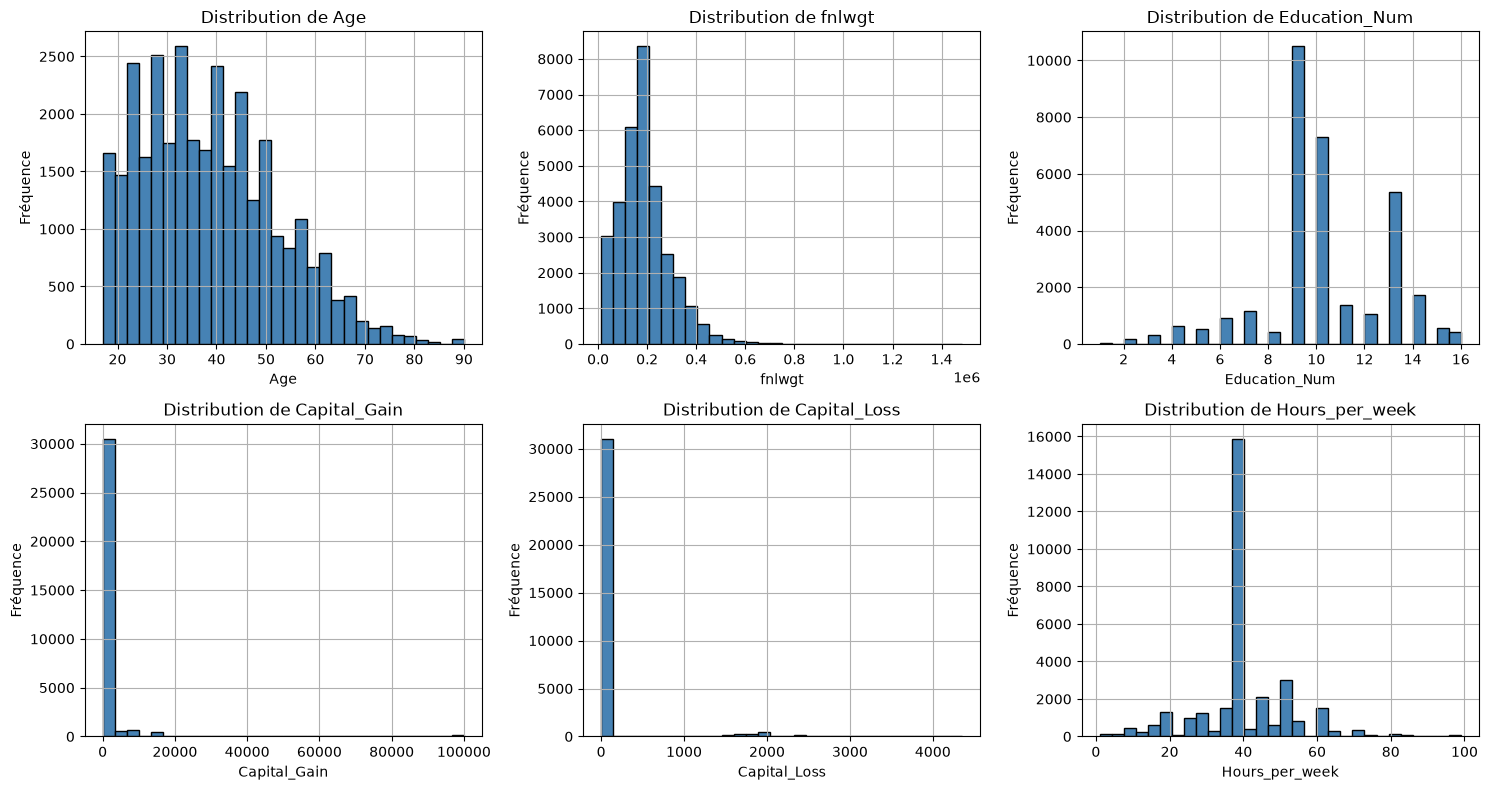

In [5]:
# Cellule 5 : Distribution des variables numériques
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

num_cols = ['Age', 'fnlwgt', 'Education_Num',
            'Capital_Gain', 'Capital_Loss', 'Hours_per_week']

for i, col in enumerate(num_cols):
    ax = axes[i//3, i%3]
    df[col].hist(bins=30, ax=ax, color='steelblue', edgecolor='black')
    ax.set_title(f'Distribution de {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Fréquence')

plt.tight_layout()
plt.show()


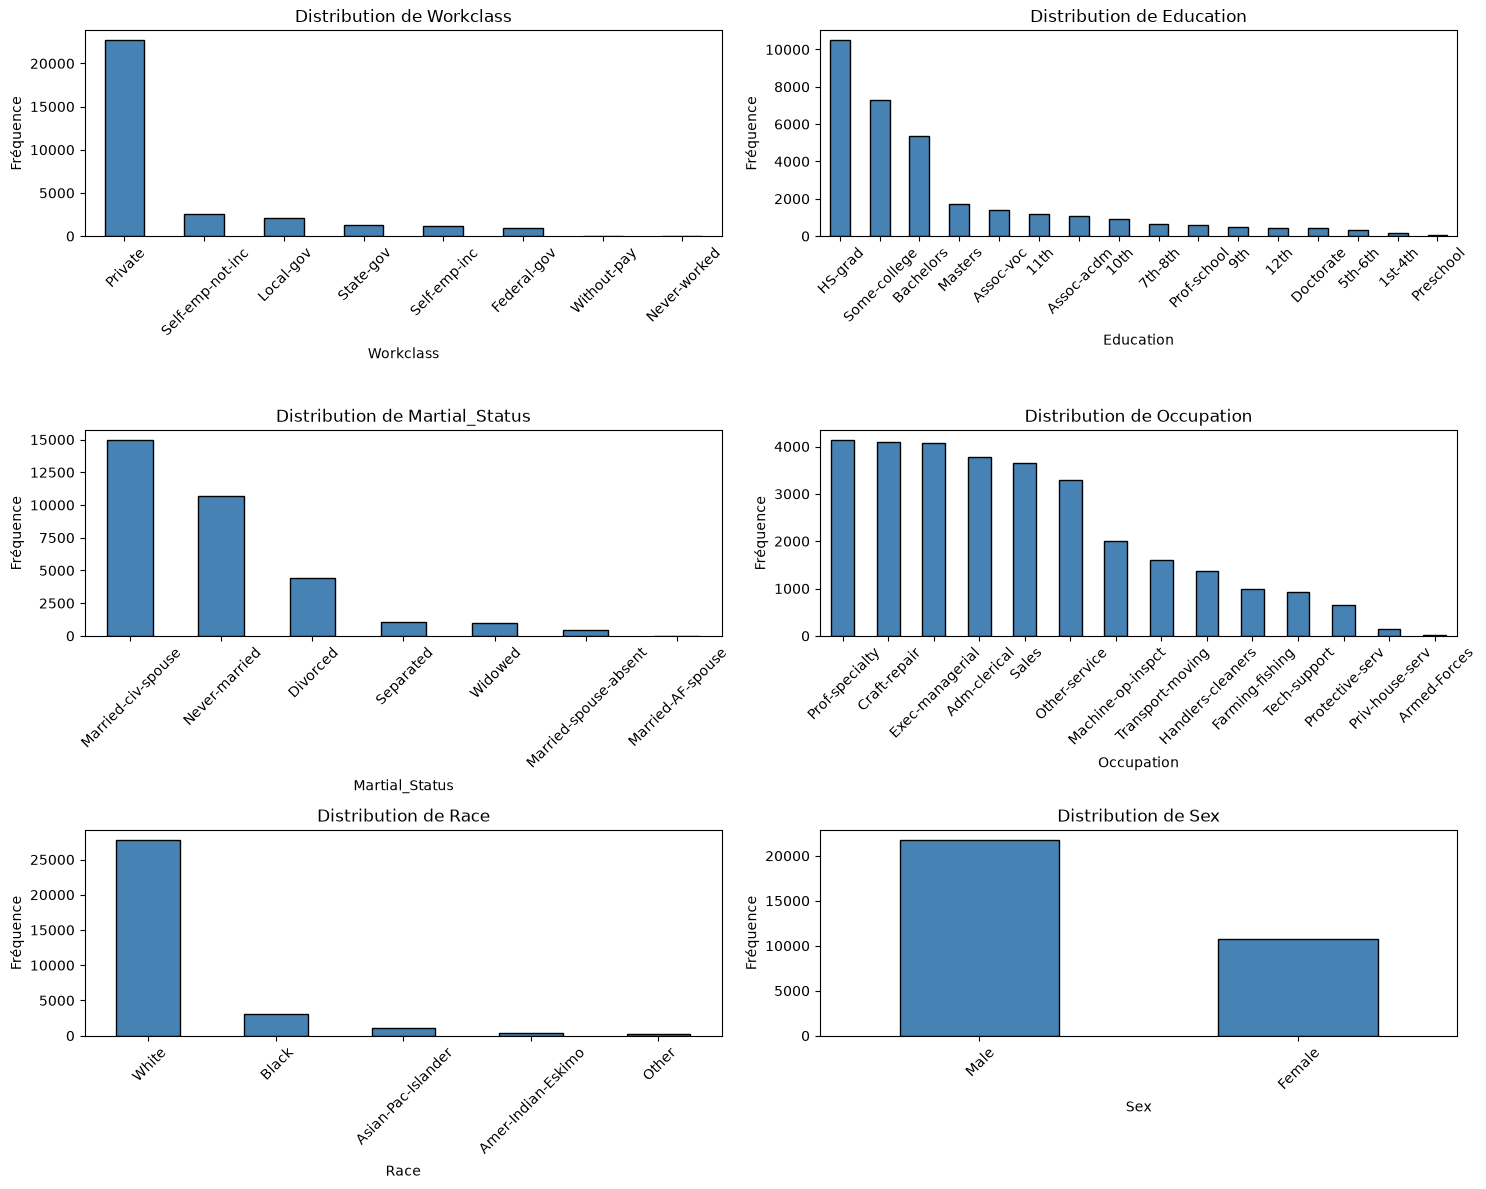

In [6]:
# Cellule 6 : Distribution des variables catégorielles
cat_cols = ['Workclass', 'Education', 'Martial_Status',
            'Occupation', 'Race', 'Sex']

fig, axes = plt.subplots(3, 2, figsize=(15, 12))

for i, col in enumerate(cat_cols):
    ax = axes[i//2, i%2]
    df[col].value_counts().plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
    ax.set_title(f'Distribution de {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Fréquence')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


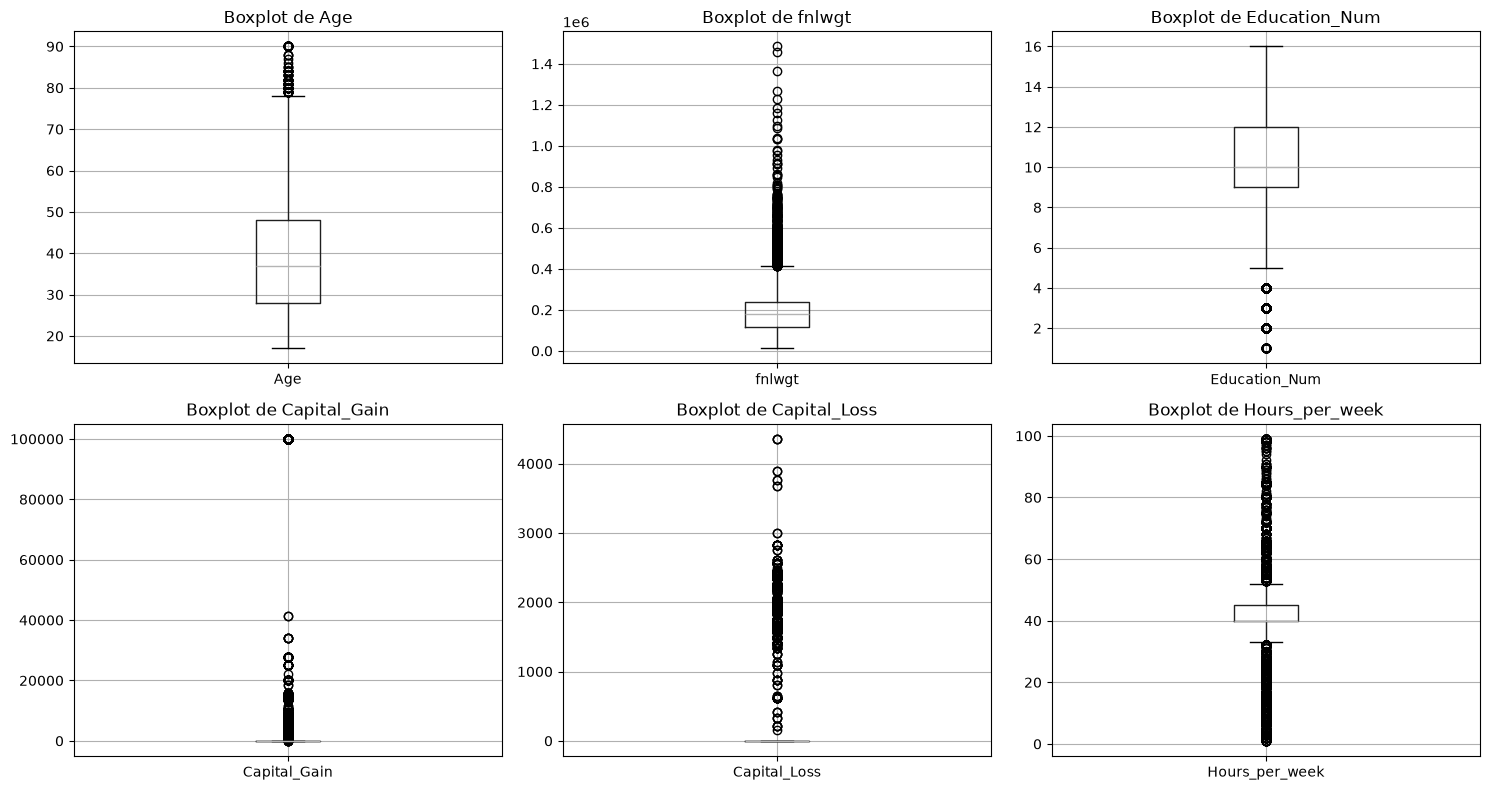

In [7]:
# Cellule 7 : Boxplots pour détecter les outliers
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

num_cols = ['Age', 'fnlwgt', 'Education_Num',
            'Capital_Gain', 'Capital_Loss', 'Hours_per_week']

for i, col in enumerate(num_cols):
    ax = axes[i//3, i%3]
    df.boxplot(column=col, ax=ax)
    ax.set_title(f'Boxplot de {col}')

plt.tight_layout()
plt.show()


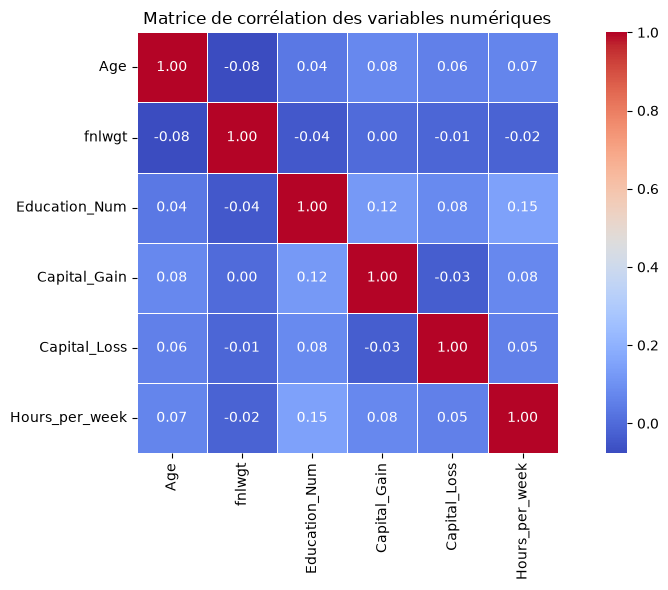

In [8]:
# Cellule 8 : Corrélation entre variables numériques
plt.figure(figsize=(10, 6))
corr_matrix = df[['Age', 'fnlwgt', 'Education_Num',
                   'Capital_Gain', 'Capital_Loss',
                   'Hours_per_week']].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f',
            cmap='coolwarm', square=True, linewidths=0.5)
plt.title("Matrice de corrélation des variables numériques")
plt.tight_layout()
plt.show()


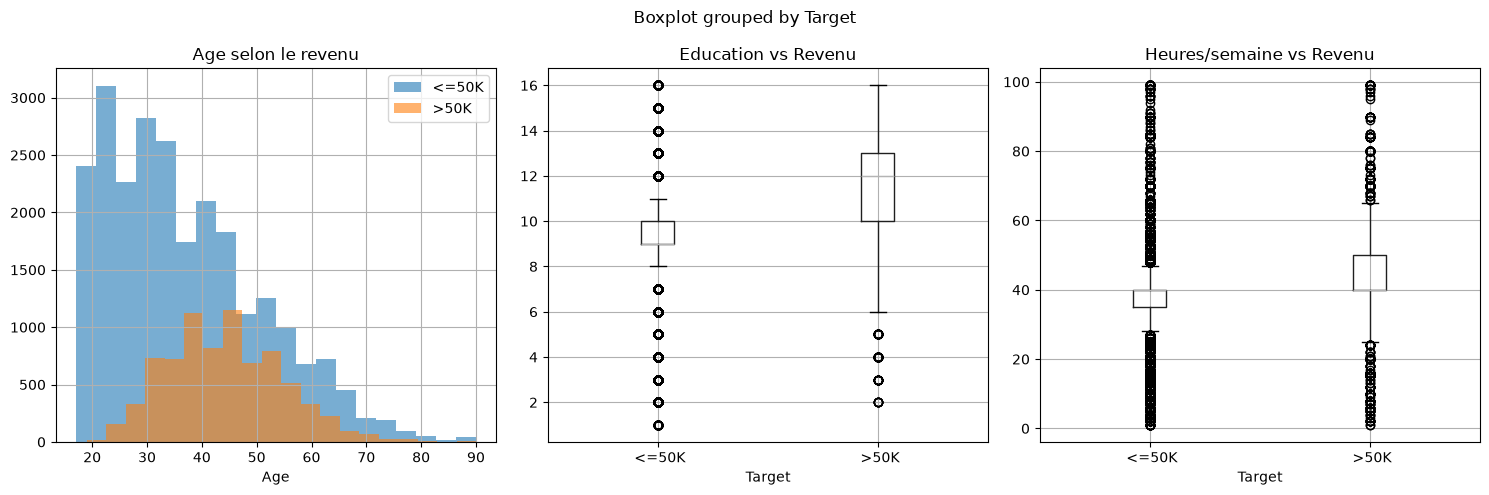

In [9]:
# Cellule 9 : Relation entre variables et la cible (Target)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Age vs Target
df.groupby('Target')['Age'].hist(alpha=0.6, ax=axes[0], bins=20)
axes[0].set_title('Age selon le revenu')
axes[0].set_xlabel('Age')
axes[0].legend(['<=50K', '>50K'])

# Education_Num vs Target
df.boxplot(column='Education_Num', by='Target', ax=axes[1])
axes[1].set_title('Education vs Revenu')
axes[1].set_xlabel('Target')

# Hours_per_week vs Target
df.boxplot(column='Hours_per_week', by='Target', ax=axes[2])
axes[2].set_title('Heures/semaine vs Revenu')
axes[2].set_xlabel('Target')

plt.tight_layout()
plt.show()


## 4. Data Preparation

### Justification des choix de nettoyage :
- **Valeurs manquantes** : Workclass (1836), Occupation (1843), Country (583) → imputation par la valeur la plus fréquente (mode) car variables catégorielles
- **Outliers** : Capital_Gain et Capital_Loss → capping IQR car vraies observations économiques
- **fnlwgt** : supprimé car non pertinent pour la prédiction
- **Encodage** : LabelEncoder pour Target, OneHotEncoder pour les nominales
- **Normalisation** : StandardScaler pour les variables numériques


In [10]:
df_test = adult_test.copy()  # pas de drop_duplicates sur le jeu de test
adult_test.info()
print(df_test.isnull().sum())
cols_na = ["Workclass", "Occupation", "Country"]
for col in cols_na:
    df_test[col] = df_test[col].fillna(df[col].mode()[0])  # mode du TRAIN (comme df_clean)

print("\nManquants après :", df_test.isnull().sum().sum())

print("\nManquants après :", df_test.isnull().sum())
df_test.head()
df_test = df_test.drop(index=0).reset_index(drop=True)  # ligne parasite du fichier test
df_test['Age'] = pd.to_numeric(df_test['Age'])
df_test['Target'] = df_test['Target'].str.strip().str.rstrip('.')  # '<=50K.' -> '<=50K'
print("\nManquants après :", df_test.isnull().sum())


<class 'pandas.DataFrame'>
RangeIndex: 16282 entries, 0 to 16281
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             16282 non-null  str    
 1   Workclass       15318 non-null  str    
 2   fnlwgt          16281 non-null  float64
 3   Education       16281 non-null  str    
 4   Education_Num   16281 non-null  float64
 5   Martial_Status  16281 non-null  str    
 6   Occupation      15315 non-null  str    
 7   Relationship    16281 non-null  str    
 8   Race            16281 non-null  str    
 9   Sex             16281 non-null  str    
 10  Capital_Gain    16281 non-null  float64
 11  Capital_Loss    16281 non-null  float64
 12  Hours_per_week  16281 non-null  float64
 13  Country         16007 non-null  str    
 14  Target          16281 non-null  str    
dtypes: float64(5), str(10)
memory usage: 3.3 MB
Age                 0
Workclass         964
fnlwgt              1
Education           1


In [11]:
# Cellule 10 : Nettoyage - Copie du dataset + Doublons + Valeurs manquantes

# 1. Travailler sur une copie pour garder l'original intact
df_clean = df.copy()


# 2. Supprimer les doublons
avant = len(df_clean)
df_clean = df_clean.drop_duplicates()
apres = len(df_clean)
print(f"Doublons supprimés : {avant - apres}")

# 3. Traiter les valeurs manquantes par le MODE (valeur la plus fréquente)
# Justification : variables catégorielles → on utilise most_frequent
for col in ['Workclass', 'Occupation', 'Country']:
    mode_val = df_clean[col].mode()[0]
    df_clean[col] = df_clean[col].fillna(mode_val)
    print(f"{col} → valeurs manquantes remplacées par : '{mode_val}'")

# 4. Vérification
print(f"\nValeurs manquantes restantes :")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])
print("✅ Aucune valeur manquante !" if df_clean.isnull().sum().sum() == 0 else "")
print(f"\nDimensions après nettoyage : {df_clean.shape}")


Doublons supprimés : 24
Workclass → valeurs manquantes remplacées par : ' Private'
Occupation → valeurs manquantes remplacées par : ' Prof-specialty'
Country → valeurs manquantes remplacées par : ' United-States'

Valeurs manquantes restantes :
Series([], dtype: int64)
✅ Aucune valeur manquante !

Dimensions après nettoyage : (32537, 15)


In [12]:
# Cellule 11 : Traitement des outliers (méthode IQR - Capping)
# Justification : Capital_Gain et Capital_Loss ont des valeurs extrêmes
# On utilise le capping (pas suppression) car ce sont de vraies observations

def cap_outliers(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df[col] = df[col].clip(lower=lower, upper=upper)
    print(f"{col} → cappé entre {lower:.1f} et {upper:.1f}")
    return df

# On cappe Capital_Gain, Capital_Loss et Hours_per_week
for col in ['Capital_Gain', 'Capital_Loss', 'Hours_per_week']:
    df_clean = cap_outliers(df_clean, col)

print(f"\n✅ Outliers traités !")
print(df_clean[['Capital_Gain', 'Capital_Loss', 'Hours_per_week']].describe())


Capital_Gain → cappé entre 0.0 et 0.0
Capital_Loss → cappé entre 0.0 et 0.0
Hours_per_week → cappé entre 32.5 et 52.5

✅ Outliers traités !
       Capital_Gain  Capital_Loss  Hours_per_week
count       32537.0       32537.0    32537.000000
mean            0.0           0.0       41.203246
std             0.0           0.0        6.187352
min             0.0           0.0       32.500000
25%             0.0           0.0       40.000000
50%             0.0           0.0       40.000000
75%             0.0           0.0       45.000000
max             0.0           0.0       52.500000


In [13]:
# Cellule 11 corrigée : Traitement des outliers

# Recharger df_clean propre depuis le début
df_clean = df.copy()
df_clean = df_clean.drop_duplicates()
for col in ['Workclass', 'Occupation', 'Country']:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# Pour Capital_Gain et Capital_Loss : garder seulement les valeurs <= 99e percentile
# Justification : 75% des valeurs sont 0, le capping IQR efface tout
# On utilise le percentile 99 à la place
for col in ['Capital_Gain', 'Capital_Loss']:
    upper = df_clean[col].quantile(0.99)
    df_clean[col] = df_clean[col].clip(upper=upper)
    print(f"{col} → cappé à {upper:.1f}")

# Pour Hours_per_week : capping IQR normal
Q1 = df_clean['Hours_per_week'].quantile(0.25)
Q3 = df_clean['Hours_per_week'].quantile(0.75)
IQR = Q3 - Q1
df_clean['Hours_per_week'] = df_clean['Hours_per_week'].clip(
    lower=Q1 - 1.5*IQR, upper=Q3 + 1.5*IQR)
print(f"Hours_per_week → cappé entre {Q1-1.5*IQR:.1f} et {Q3+1.5*IQR:.1f}")

print("\n✅ Outliers traités !")
print(df_clean[['Capital_Gain', 'Capital_Loss', 'Hours_per_week']].describe())


Capital_Gain → cappé à 15024.0
Capital_Loss → cappé à 1980.0
Hours_per_week → cappé entre 32.5 et 52.5

✅ Outliers traités !
       Capital_Gain  Capital_Loss  Hours_per_week
count  32537.000000  32537.000000    32537.000000
mean     634.278913     83.861880       41.203246
std     2521.975203    383.089541        6.187352
min        0.000000      0.000000       32.500000
25%        0.000000      0.000000       40.000000
50%        0.000000      0.000000       40.000000
75%        0.000000      0.000000       45.000000
max    15024.000000   1980.000000       52.500000


In [14]:
# Cellule 12 : Encodage des variables catégorielles
from sklearn.preprocessing import LabelEncoder

# 1. Supprimer fnlwgt (non pertinent pour la prédiction)
df_clean = df_clean.drop(columns='fnlwgt')
df_test = df_test.drop(columns='fnlwgt')
print("✅ fnlwgt supprimé")

# 2. LabelEncoder pour la variable cible Target (binaire : <=50K / >50K)
# Justification : variable ordinale binaire → LabelEncoder suffisant
le = LabelEncoder()
df_clean['Target'] = le.fit_transform(df_clean['Target'].str.strip())
df_test['Target'] = le.transform(df_test['Target'].str.strip())
print(f"Target encodé : {dict(zip(le.classes_, le.transform(le.classes_)))}")

# 2b. Mêmes bornes d'outliers que le train appliquées au test
for col in ['Capital_Gain', 'Capital_Loss', 'Hours_per_week']:
    df_test[col] = df_test[col].clip(lower=df_clean[col].min(), upper=df_clean[col].max())

# 3. OneHotEncoding pour les variables nominales
# Justification : pas d'ordre entre les catégories → OneHotEncoder
cat_cols = ['Workclass', 'Education', 'Martial_Status',
            'Occupation', 'Relationship', 'Race', 'Sex', 'Country']

df_clean = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True)
# drop_first=False sur le test : la catégorie de référence est celle du TRAIN, pas celle du test
df_test = pd.get_dummies(df_test, columns=cat_cols, drop_first=False)
# Aligne le test sur les colonnes du train (ajoute les manquantes à 0, retire les en trop)
df_test = df_test.reindex(columns=df_clean.columns, fill_value=0)

print(f"\n✅ Encodage terminé !")
print(f"Dimensions après encodage : {df_clean.shape}")
df_test.head(2)
df_test.shape


✅ fnlwgt supprimé
Target encodé : {'<=50K': np.int64(0), '>50K': np.int64(1)}

✅ Encodage terminé !
Dimensions après encodage : (32537, 97)


(16281, 97)

In [15]:
# Cellule 13 : Normalisation des variables numériques
from sklearn.preprocessing import StandardScaler

# Justification : StandardScaler car les algorithmes comme KNN et K-Means
# sont sensibles aux échelles différentes (Age vs Capital_Gain par exemple)

num_cols = ['Age', 'Education_Num', 'Capital_Gain',
            'Capital_Loss', 'Hours_per_week']

scaler = StandardScaler()
df_clean[num_cols] = scaler.fit_transform(df_clean[num_cols])
df_test[num_cols] = scaler.transform(df_test[num_cols])  # transform seulement (scaler appris sur le train)

print("✅ Normalisation terminée !")
print("\nMoyennes après normalisation (doivent être proches de 0) :")
print(df_clean[num_cols].mean().round(4))
print("\nÉcarts-types après normalisation (doivent être proches de 1) :")
print(df_clean[num_cols].std().round(4))


✅ Normalisation terminée !

Moyennes après normalisation (doivent être proches de 0) :
Age              -0.0
Education_Num     0.0
Capital_Gain      0.0
Capital_Loss     -0.0
Hours_per_week   -0.0
dtype: float64

Écarts-types après normalisation (doivent être proches de 1) :
Age               1.0
Education_Num     1.0
Capital_Gain      1.0
Capital_Loss      1.0
Hours_per_week    1.0
dtype: float64


In [16]:
# Cellule 14 : Sauvegarde du dataset nettoyé + Feature Engineering
# Feature Engineering : création d'une variable age_group
df_clean['age_group'] = pd.cut(
    scaler.inverse_transform(
        df_clean[['Age', 'Education_Num', 'Capital_Gain',
                  'Capital_Loss', 'Hours_per_week']]
    )[:, 0],
    bins=[0, 30, 45, 60, 100],
    labels=['Jeune', 'Adulte', 'Senior', 'Aine']
)
df_test['age_group'] = pd.cut(
    scaler.inverse_transform(
        df_test[['Age', 'Education_Num', 'Capital_Gain',
                  'Capital_Loss', 'Hours_per_week']]
    )[:, 0],
    bins=[0, 30, 45, 60, 100],
    labels=['Jeune', 'Adulte', 'Senior', 'Aine']
)
le_age = LabelEncoder()
df_clean['age_group'] = le_age.fit_transform(
    df_clean['age_group'].astype(str))

df_test['age_group'] = le_age.transform(
    df_test['age_group'].astype(str))


# Sauvegarde
df_clean.to_csv('adult_cleaned.csv', index=False)
print("✅ Fichier adult_cleaned.csv sauvegardé !")
print(f"Dimensions finales : {df_clean.shape}")


✅ Fichier adult_cleaned.csv sauvegardé !
Dimensions finales : (32537, 98)


C:\Users\utilisateur\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\utilisateur\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\utilisateur\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\utilisateur\anaconda3\Lib\subprocess.py", line 555, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~

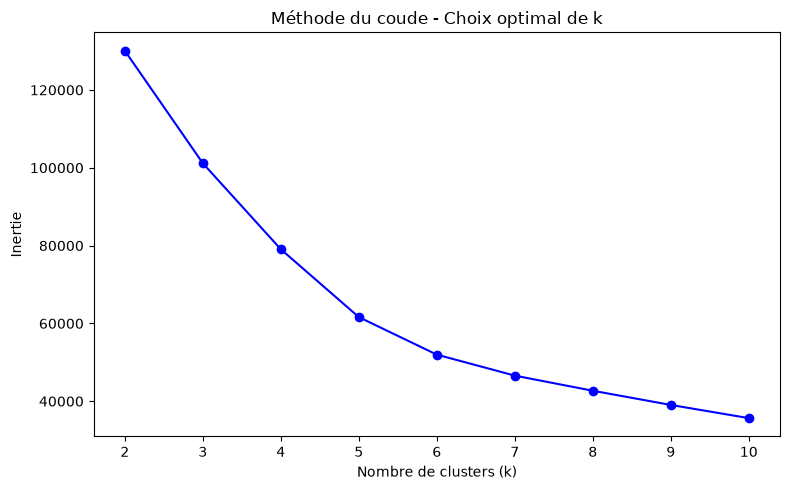

In [17]:
# Cellule 15 : K-Means - Méthode du coude
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# On utilise les 5 variables numériques pour le clustering
X_cluster = df_clean[['Age', 'Education_Num', 'Capital_Gain',
                       'Capital_Loss', 'Hours_per_week']].values

# Méthode du coude
inerties = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster)
    inerties.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inerties, 'bo-')
plt.xlabel('Nombre de clusters (k)')
plt.ylabel('Inertie')
plt.title('Méthode du coude - Choix optimal de k')
plt.xticks(K_range)
plt.tight_layout()
plt.show()


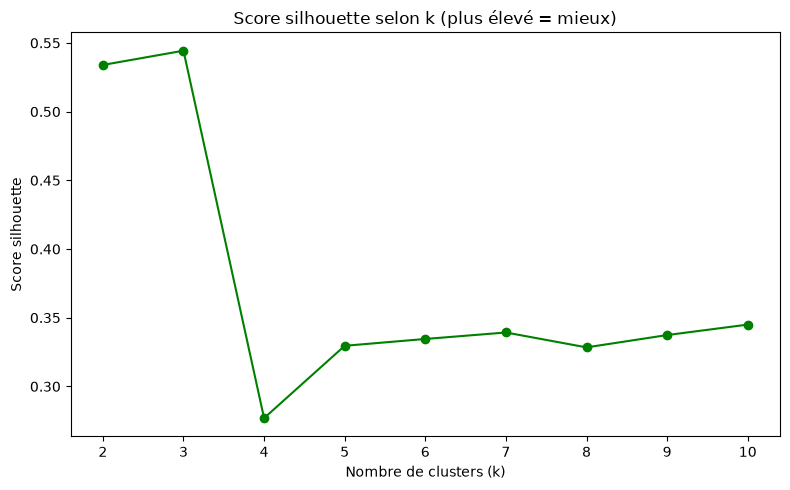

2     0.5340
3     0.5443
4     0.2769
5     0.3296
6     0.3345
7     0.3392
8     0.3284
9     0.3374
10    0.3450
dtype: float64


In [18]:
# Cellule 15b : Score silhouette selon k (aide au choix de k)
from sklearn.metrics import silhouette_score

scores_sil = []
for k in K_range:
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_cluster)
    # échantillon de 5000 points pour accélérer le calcul
    scores_sil.append(silhouette_score(X_cluster, labels, sample_size=5000, random_state=42))

plt.figure(figsize=(8, 5))
plt.plot(K_range, scores_sil, 'go-')
plt.xlabel('Nombre de clusters (k)')
plt.ylabel('Score silhouette')
plt.title('Score silhouette selon k (plus élevé = mieux)')
plt.xticks(K_range)
plt.tight_layout()
plt.show()

print(pd.Series(scores_sil, index=list(K_range)).round(4))


✅ K-Means appliqué avec k=5
Score Silhouette : 0.3259


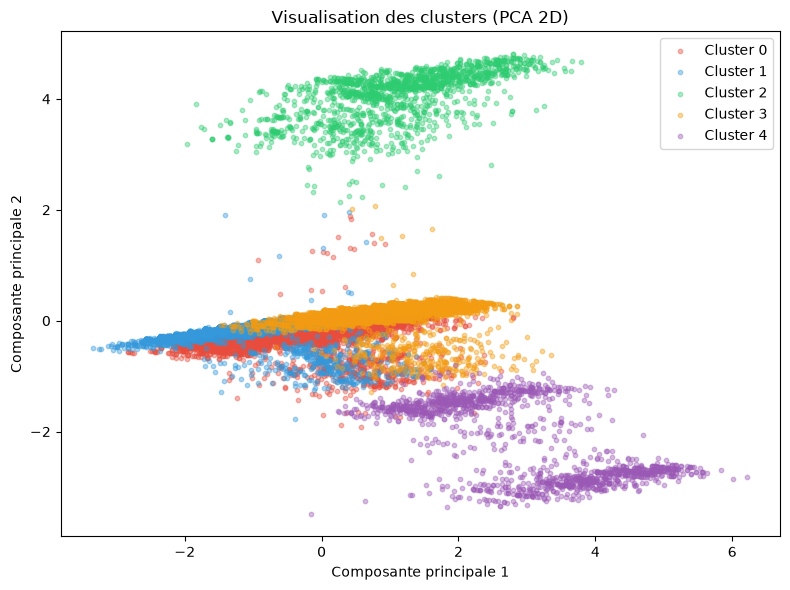

In [19]:
# Cellule 16 : Application K-Means avec k=K_CHOISI + Visualisation
from sklearn.metrics import silhouette_score

# k choisi d'après le coude (Cellule 15) et le silhouette (Cellule 15b) ; modifier ici pour changer k
K_CHOISI = 5
kmeans = KMeans(n_clusters=K_CHOISI, random_state=42, n_init=10)
df_clean['Cluster'] = kmeans.fit_predict(X_cluster)

# Score silhouette
sil_score = silhouette_score(X_cluster, df_clean['Cluster'])
print(f"✅ K-Means appliqué avec k={K_CHOISI}")
print(f"Score Silhouette : {sil_score:.4f}")

# Visualisation avec PCA (réduction à 2D pour affichage)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_cluster)

plt.figure(figsize=(8, 6))
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c']
for i in range(K_CHOISI):
    mask = df_clean['Cluster'] == i
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                c=colors[i], label=f'Cluster {i}', alpha=0.4, s=10)

plt.title('Visualisation des clusters (PCA 2D)')
plt.xlabel('Composante principale 1')
plt.ylabel('Composante principale 2')
plt.legend()
plt.tight_layout()
plt.show()


=== PROFIL MOYEN DE CHAQUE CLUSTER ===

          Age  Education_Num  Capital_Gain  Capital_Loss  Hours_per_week
Cluster                                                                 
0        53.4            9.4         185.0           1.2            38.5
1        28.2            9.8         103.9           0.4            37.8
2        41.6           11.0           0.0        1824.8            42.9
3        39.0           10.9         170.3           0.6            50.0
4        45.6           12.1       11248.0           0.0            44.6

=== TAILLE DE CHAQUE CLUSTER ===
Cluster
0     8564
1    13964
2     1484
3     7067
4     1458
Name: count, dtype: int64


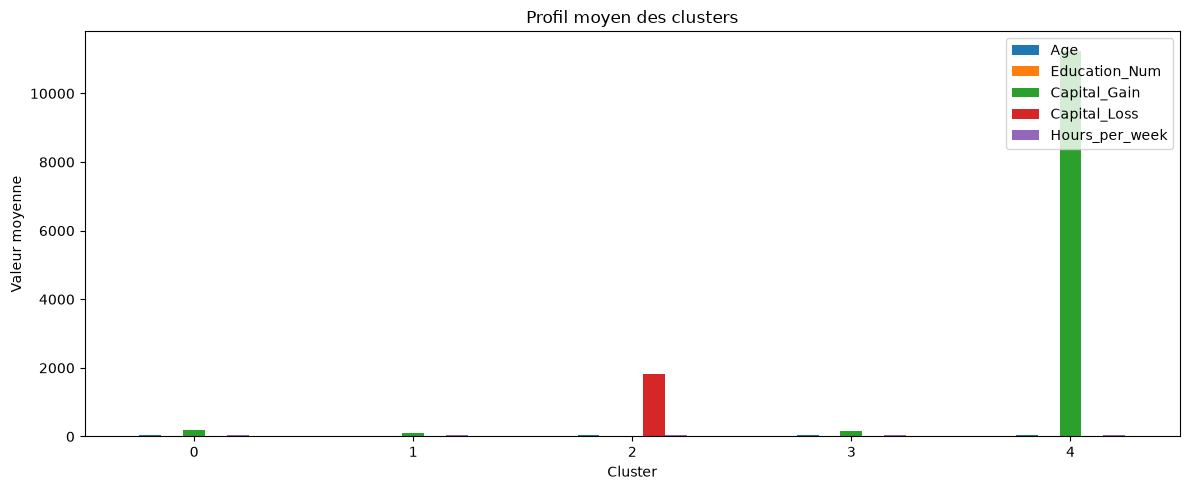

In [20]:
# Cellule 17 : Interprétation des clusters
# On recrée les valeurs originales pour interpréter
original_cols = ['Age', 'Education_Num', 'Capital_Gain',
                 'Capital_Loss', 'Hours_per_week']

X_original = scaler.inverse_transform(
    df_clean[original_cols].values)

df_interp = pd.DataFrame(X_original, columns=original_cols)
df_interp['Cluster'] = df_clean['Cluster'].values

print("=== PROFIL MOYEN DE CHAQUE CLUSTER ===\n")
profils = df_interp.groupby('Cluster').mean().round(1)
print(profils)

print("\n=== TAILLE DE CHAQUE CLUSTER ===")
print(df_clean['Cluster'].value_counts().sort_index())

# Visualisation
profils.plot(kind='bar', figsize=(12, 5))
plt.title('Profil moyen des clusters')
plt.xlabel('Cluster')
plt.ylabel('Valeur moyenne')
plt.xticks(rotation=0)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


## 6. Classification

**Problématique** : Prédire si un individu gagne >50K ou <=50K.

**Modèles utilisés** : Decision Tree, Random Forest, KNN
**Métrique principale** : Accuracy, Precision, Recall, F1-Score



In [21]:
# Cellule 18 : Préparation des données pour la classification

X_train = df_clean.drop(columns=['Target', 'Cluster'], errors='ignore')
y_train = df_clean['Target']

X_test = df_test.drop(columns=['Target', 'Cluster'], errors='ignore')
y_test = df_test['Target']

print("Données séparées par le professeur :")
print(f"Train : {X_train.shape}")
print(f"Test  : {X_test.shape}")

print("\nDistribution Target - Train :")
print(y_train.value_counts())

print("\nDistribution Target - Test :")
print(y_test.value_counts())

Données séparées par le professeur :
Train : (32537, 97)
Test  : (16281, 97)

Distribution Target - Train :
Target
0    24698
1     7839
Name: count, dtype: int64

Distribution Target - Test :
Target
0    12435
1     3846
Name: count, dtype: int64


In [22]:
# Cellule 19 : Les 3 modèles de classification
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

modeles = {
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

resultats = {}

for nom, modele in modeles.items():
    modele.fit(X_train, y_train)
    y_pred = modele.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    resultats[nom] = acc
    print(f"\n{'='*40}")
    print(f"Modèle : {nom}")
    print(f"Accuracy : {acc:.4f}")
    print(classification_report(y_test, y_pred,
          target_names=['<=50K', '>50K']))



Modèle : Decision Tree
Accuracy : 0.8522
              precision    recall  f1-score   support

       <=50K       0.87      0.96      0.91     12435
        >50K       0.78      0.52      0.62      3846

    accuracy                           0.85     16281
   macro avg       0.82      0.74      0.77     16281
weighted avg       0.85      0.85      0.84     16281


Modèle : Random Forest
Accuracy : 0.8444
              precision    recall  f1-score   support

       <=50K       0.88      0.92      0.90     12435
        >50K       0.70      0.61      0.65      3846

    accuracy                           0.84     16281
   macro avg       0.79      0.76      0.77     16281
weighted avg       0.84      0.84      0.84     16281


Modèle : KNN
Accuracy : 0.8372
              precision    recall  f1-score   support

       <=50K       0.88      0.91      0.89     12435
        >50K       0.67      0.62      0.64      3846

    accuracy                           0.84     16281
   macro avg

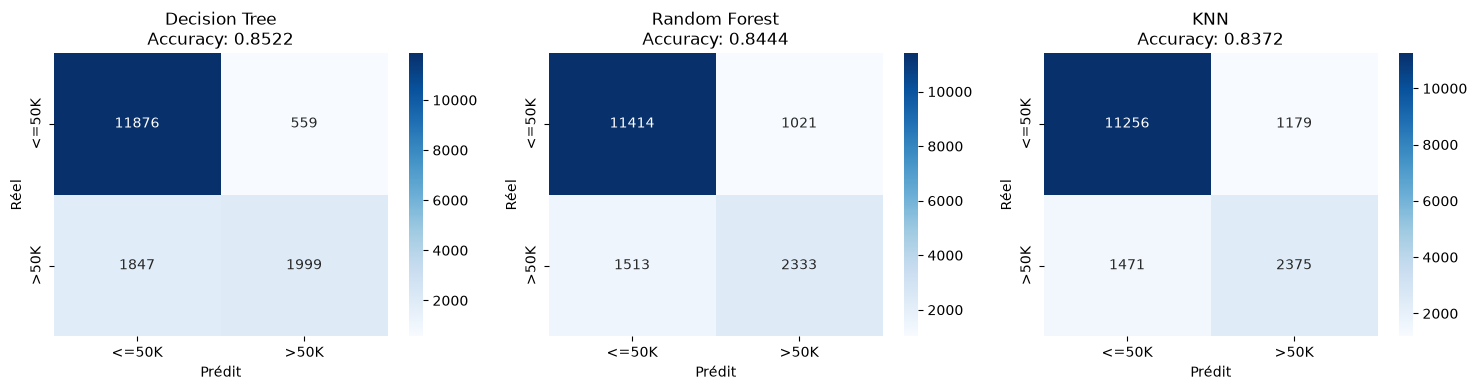

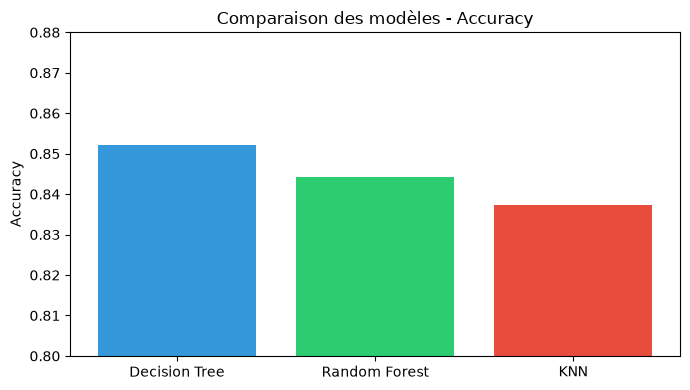

In [23]:
# Cellule 20 : Comparaison visuelle + Matrice de confusion
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

modeles_fits = {
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

for i, (nom, modele) in enumerate(modeles_fits.items()):
    modele.fit(X_train, y_train)
    y_pred = modele.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', ax=axes[i],
                cmap='Blues', xticklabels=['<=50K','>50K'],
                yticklabels=['<=50K','>50K'])
    axes[i].set_title(f'{nom}\nAccuracy: {accuracy_score(y_test,y_pred):.4f}')
    axes[i].set_ylabel('Réel')
    axes[i].set_xlabel('Prédit')

plt.tight_layout()
plt.show()

# Graphique comparatif
plt.figure(figsize=(7, 4))
plt.bar(resultats.keys(), resultats.values(),
        color=['#3498db', '#2ecc71', '#e74c3c'])
plt.ylim(0.80, 0.88)
plt.title('Comparaison des modèles - Accuracy')
plt.ylabel('Accuracy')
plt.tight_layout()
plt.show()


### Évaluation approfondie (ajout)

Le dataset est déséquilibré (≈76 % de `<=50K`), donc l'accuracy seule est trompeuse : un modèle qui prédit toujours `<=50K` obtient déjà ≈76 %. On ajoute :
- la visualisation du **Decision Tree** ;
- deux **modèles de référence** (Dummy, Régression logistique) pour mesurer le gain réel des 3 modèles ;
- les métriques de la classe `>50K` (Precision, Recall, F1), les courbes **ROC / AUC** et **Précision-Rappel** ;
- l'**importance des variables** (Random Forest).


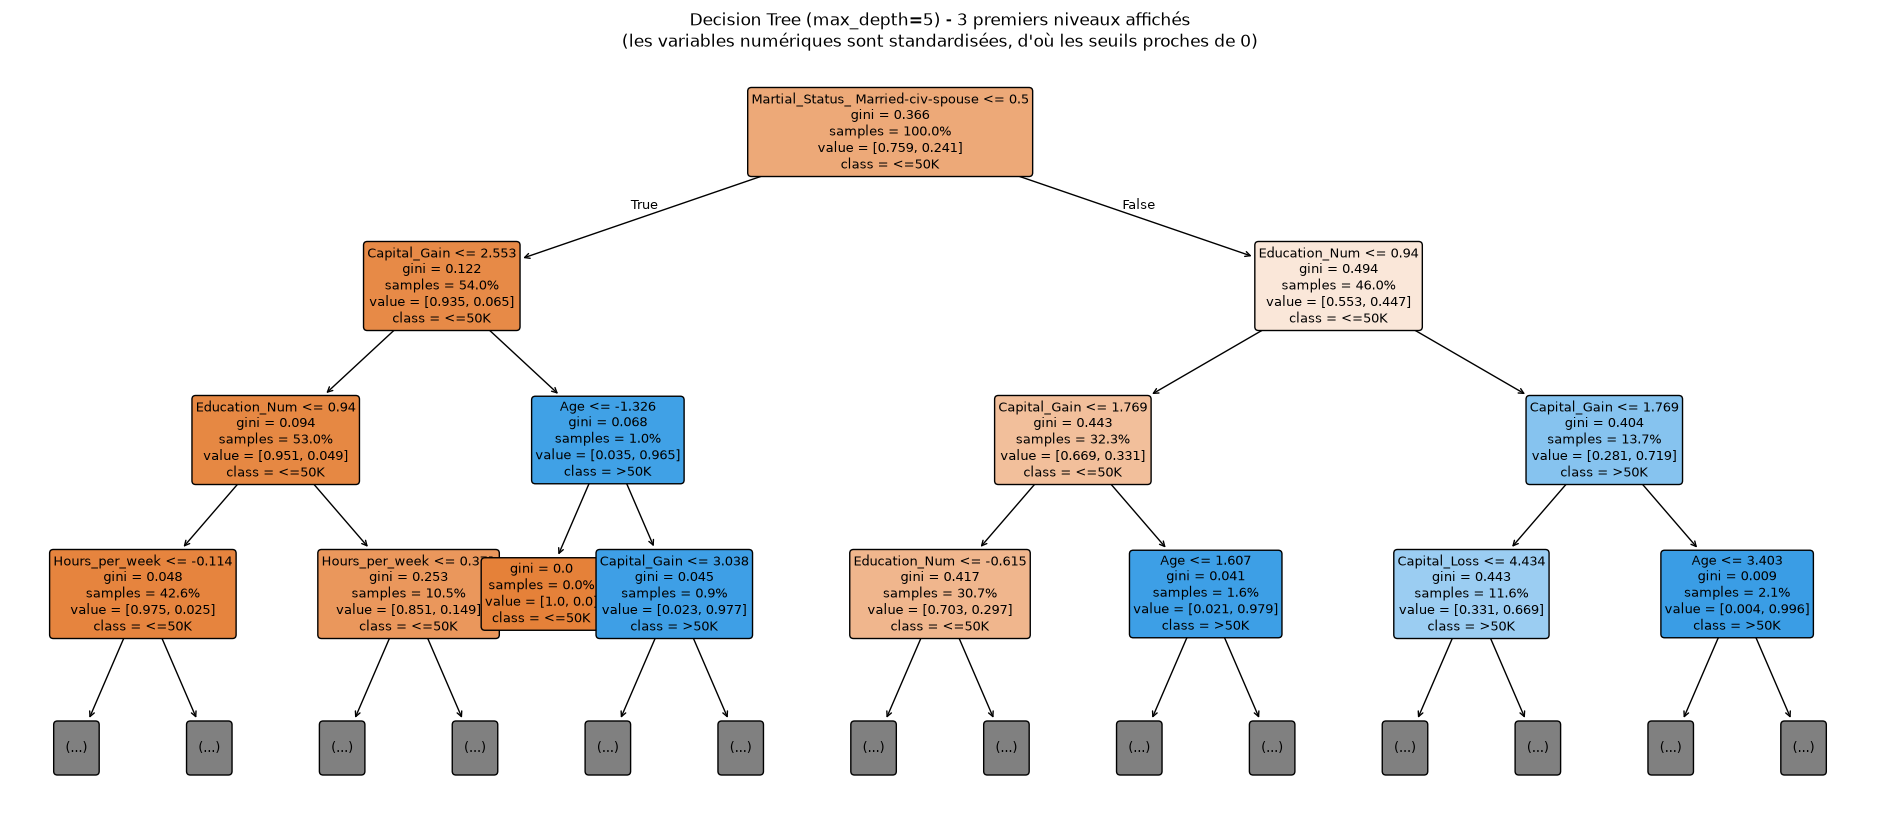

=== RÈGLES DE L'ARBRE (3 premiers niveaux) ===
|--- Martial_Status_ Married-civ-spouse <= 0.50
|   |--- Capital_Gain <= 2.55
|   |   |--- Education_Num <= 0.94
|   |   |   |--- Hours_per_week <= -0.11
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Hours_per_week >  -0.11
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- Education_Num >  0.94
|   |   |   |--- Hours_per_week <= 0.37
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Hours_per_week >  0.37
|   |   |   |   |--- truncated branch of depth 2
|   |--- Capital_Gain >  2.55
|   |   |--- Age <= -1.33
|   |   |   |--- class: 0
|   |   |--- Age >  -1.33
|   |   |   |--- Capital_Gain <= 3.04
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Capital_Gain >  3.04
|   |   |   |   |--- truncated branch of depth 2
|--- Martial_Status_ Married-civ-spouse >  0.50
|   |--- Education_Num <= 0.94
|   |   |--- Capital_Gain <= 1.77
|   |   |   |--- Education_Num <= -0.62
|   |   |   

In [24]:
# Cellule 20a : Visualisation du Decision Tree
from sklearn.tree import plot_tree, export_text

# Même arbre que la Cellule 19 ; gini = impureté du nœud (0 = pur, 0.5 = mélange parfait)
arbre = DecisionTreeClassifier(max_depth=5, random_state=42)
arbre.fit(X_train, y_train)

# On n'affiche que 3 niveaux pour rester lisible
plt.figure(figsize=(24, 10))
plot_tree(arbre, feature_names=list(X_train.columns),
          class_names=['<=50K', '>50K'], filled=True, rounded=True,
          proportion=True, max_depth=3, fontsize=9)
plt.title("Decision Tree (max_depth=5) - 3 premiers niveaux affichés\n"
          "(les variables numériques sont standardisées, d'où les seuils proches de 0)")
plt.show()

print("=== RÈGLES DE L'ARBRE (3 premiers niveaux) ===")
print(export_text(arbre, feature_names=list(X_train.columns), max_depth=3))


In [25]:
# Cellule 20b : Modèles de référence + métriques complètes (classe >50K)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

# Dummy = référence minimale : tout modèle doit faire mieux
tous_modeles = {
    'Dummy (classe majoritaire)': DummyClassifier(strategy='most_frequent'),
    'Régression logistique': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

lignes = []
probas = {}
for nom, modele in tous_modeles.items():
    modele.fit(X_train, y_train)
    y_pred = modele.predict(X_test)
    y_proba = modele.predict_proba(X_test)[:, 1]   # probabilité d'être >50K (pour ROC / PR)
    probas[nom] = y_proba
    lignes.append({
        'Modèle': nom,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (>50K)': precision_score(y_test, y_pred, zero_division=0),
        'Recall (>50K)': recall_score(y_test, y_pred),
        'F1 (>50K)': f1_score(y_test, y_pred),
        'AUC ROC': roc_auc_score(y_test, y_proba),
        'AP (Préc.-Rappel)': average_precision_score(y_test, y_proba)
    })

df_metriques = pd.DataFrame(lignes).set_index('Modèle').round(4)
df_metriques


,Accuracy,Precision (>50K),Recall (>50K),F1 (>50K),AUC ROC,AP (Préc.-Rappel)
Modèle,,,,,,
Dummy (classe majoritaire),0.7638,0.0000,0.0000,0.0000,0.5000,0.2362
Régression logistique,0.8509,0.7301,0.5853,0.6497,0.9040,0.7617
Decision Tree,0.8522,0.7815,0.5198,0.6243,0.8843,0.6965
Random Forest,0.8444,0.6956,0.6066,0.6481,0.8873,0.7265
KNN,0.8372,0.6683,0.6175,0.6419,0.8651,0.6619


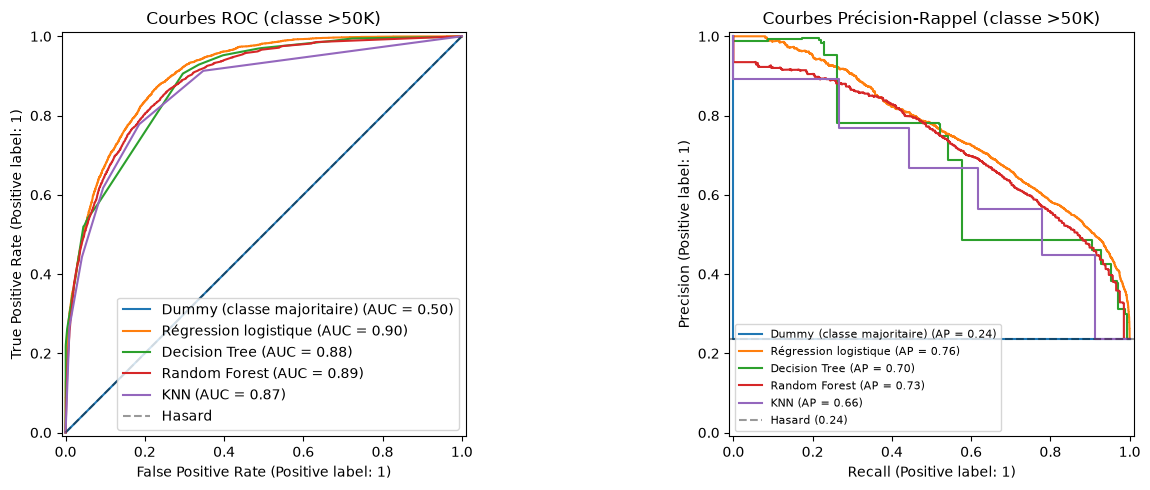

In [26]:
# Cellule 20c : Courbes ROC et Précision-Rappel
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

# ROC : recall vs faux positifs selon le seuil ; PR : precision vs recall
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for nom, y_proba in probas.items():
    RocCurveDisplay.from_predictions(y_test, y_proba, name=nom, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, y_proba, name=nom, ax=axes[1])

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Hasard')
axes[0].set_title('Courbes ROC (classe >50K)')
axes[0].legend(loc='lower right')

prevalence = y_test.mean()   # hasard en Précision-Rappel = proportion de >50K
axes[1].axhline(prevalence, color='k', linestyle='--', alpha=0.4,
                label=f'Hasard ({prevalence:.2f})')
axes[1].set_title('Courbes Précision-Rappel (classe >50K)')
axes[1].legend(loc='lower left', fontsize=8)

plt.tight_layout()
plt.show()


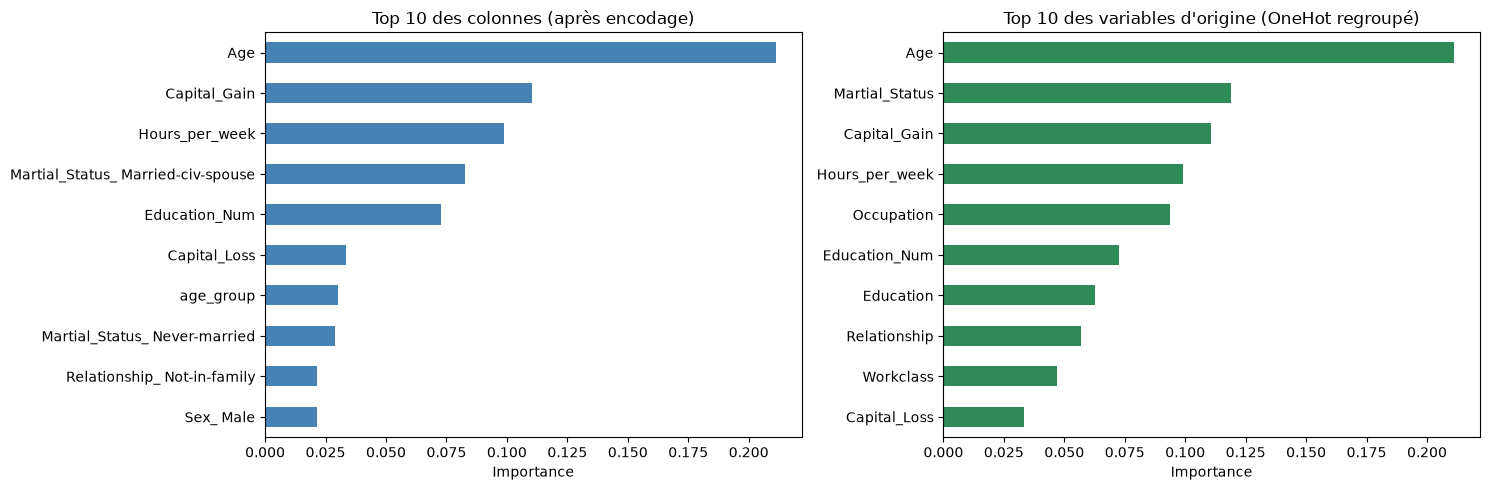

=== TOP 10 DES VARIABLES D'ORIGINE ===
Age               0.2113
Martial_Status    0.1189
Capital_Gain      0.1105
Hours_per_week    0.0990
Occupation        0.0937
Education_Num     0.0726
Education         0.0626
Relationship      0.0568
Workclass         0.0470
Capital_Loss      0.0335
dtype: float64


In [27]:
# Cellule 20d : Importance des variables (Random Forest)
# Importance = contribution moyenne de la variable à la baisse du Gini
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
importances = pd.Series(rf.feature_importances_,
                        index=X_train.columns).sort_values(ascending=False)

# Regrouper les colonnes OneHot par variable d'origine
variables_cat = ['Workclass', 'Education', 'Martial_Status', 'Occupation',
                 'Relationship', 'Race', 'Sex', 'Country']

def variable_origine(col):
    for v in variables_cat:
        if col.startswith(v + '_') and col != 'Education_Num':
            return v
    return col

importances_var = importances.groupby(variable_origine).sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
importances.head(10)[::-1].plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Top 10 des colonnes (après encodage)')
importances_var.head(10)[::-1].plot(kind='barh', ax=axes[1], color='seagreen')
axes[1].set_title("Top 10 des variables d'origine (OneHot regroupé)")
for ax in axes:
    ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

print("=== TOP 10 DES VARIABLES D'ORIGINE ===")
print(importances_var.head(10).round(4))


### Optimisation des hyperparamètres (GridSearchCV)

Les hyperparamètres des 3 modèles (`max_depth=5`, `n_neighbors=5`, etc.) étaient fixés arbitrairement. On les optimise avec `GridSearchCV` :
- la recherche se fait par **validation croisée à 5 plis sur le train uniquement** ;
- la métrique optimisée est le **F1 de la classe `>50K`** (adaptée au déséquilibre) ;
- `adult_test` n'est utilisé **qu'une seule fois**, pour évaluer les meilleurs modèles trouvés.


In [28]:
# Cellule 20e : GridSearchCV - optimisation des hyperparamètres
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import time

SCORING = 'f1'   # métrique optimisée (classe >50K) ; autres choix possibles : 'roc_auc', 'accuracy'
# Validation croisée sur le train : le test ne sert pas à choisir les paramètres
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grilles = {
    'Decision Tree': (DecisionTreeClassifier(random_state=42), {
        'criterion': ['gini', 'entropy'],
        'max_depth': [3, 5, 7, 10, None],
        'min_samples_leaf': [1, 5, 10, 20]}),
    'Random Forest': (RandomForestClassifier(random_state=42), {
        'n_estimators': [100, 200],
        'max_depth': [8, 12, None],
        'min_samples_leaf': [1, 5]}),
    'KNN': (KNeighborsClassifier(), {
        'n_neighbors': [3, 5, 7, 11, 15, 21],
        'weights': ['uniform', 'distance'],
        'p': [1, 2]})
}

meilleurs_modeles = {}
lignes_gs = []
for nom, (modele, grille) in grilles.items():
    debut = time.time()
    gs = GridSearchCV(modele, grille, scoring=SCORING, cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)                      # recherche sur le TRAIN uniquement
    best = gs.best_estimator_
    meilleurs_modeles[nom] = best

    y_pred = best.predict(X_test)                 # adult_test utilisé une seule fois
    y_proba = best.predict_proba(X_test)[:, 1]
    lignes_gs.append({
        'Modèle': nom,
        f'{SCORING} CV (train)': gs.best_score_,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (>50K)': precision_score(y_test, y_pred, zero_division=0),
        'Recall (>50K)': recall_score(y_test, y_pred),
        'F1 (>50K)': f1_score(y_test, y_pred),
        'AUC ROC': roc_auc_score(y_test, y_proba)
    })
    print(f"{nom} ({time.time() - debut:.0f}s) -> {gs.best_params_}")

df_gs = pd.DataFrame(lignes_gs).set_index('Modèle').round(4)
df_gs


Decision Tree (17s) -> {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 20}
Random Forest (63s) -> {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 100}
KNN (170s) -> {'n_neighbors': 21, 'p': 2, 'weights': 'uniform'}


,f1 CV (train),Accuracy,Precision (>50K),Recall (>50K),F1 (>50K),AUC ROC
Modèle,,,,,,
Decision Tree,0.6719,0.8546,0.7391,0.5944,0.6589,0.8960
Random Forest,0.6687,0.8627,0.7756,0.5894,0.6698,0.9142
KNN,0.6708,0.8474,0.6942,0.6329,0.6621,0.8974


Modèle                      Decision Tree  Random Forest     KNN
Accuracy (défaut)                  0.8522         0.8444  0.8372
Recall (>50K) (défaut)             0.5198         0.6066  0.6175
F1 (>50K) (défaut)                 0.6243         0.6481  0.6419
AUC ROC (défaut)                   0.8843         0.8873  0.8651
Accuracy (GridSearch)              0.8546         0.8627  0.8474
Recall (>50K) (GridSearch)         0.5944         0.5894  0.6329
F1 (>50K) (GridSearch)             0.6589         0.6698  0.6621
AUC ROC (GridSearch)               0.8960         0.9142  0.8974


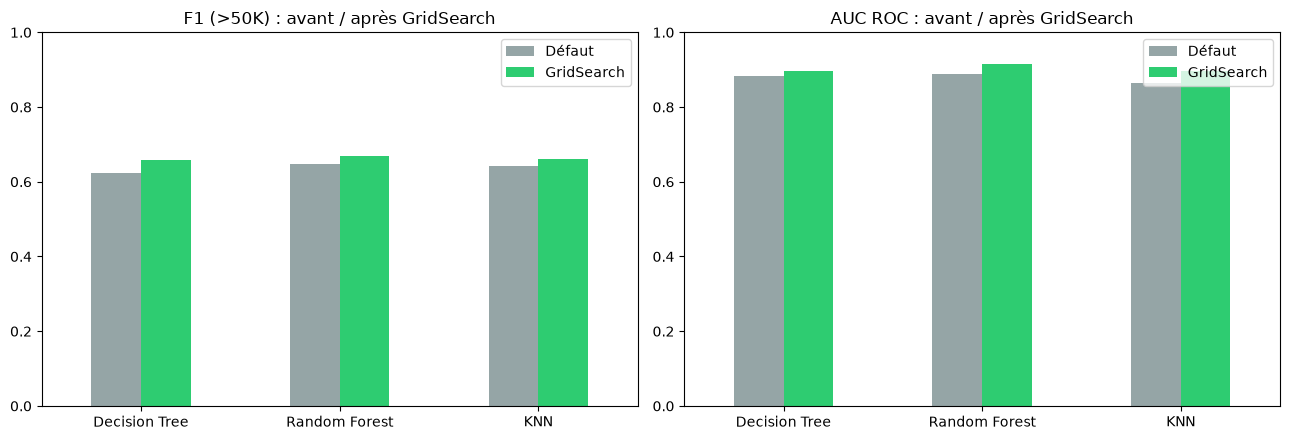

In [29]:
# Cellule 20f : Comparaison avant / après GridSearch (sur adult_test)
modeles_gs = ['Decision Tree', 'Random Forest', 'KNN']
metriques = ['Accuracy', 'Recall (>50K)', 'F1 (>50K)', 'AUC ROC']

# avant = paramètres par défaut (20b) ; après = meilleurs paramètres (20e)
avant = df_metriques.loc[modeles_gs, metriques]
apres = df_gs.loc[modeles_gs, metriques]
comparaison = avant.join(apres, lsuffix=' (défaut)', rsuffix=' (GridSearch)')
print(comparaison.round(4).T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, m in zip(axes, ['F1 (>50K)', 'AUC ROC']):
    pd.DataFrame({'Défaut': avant[m], 'GridSearch': apres[m]}).plot(
        kind='bar', ax=ax, color=['#95a5a6', '#2ecc71'], rot=0)
    ax.set_title(f'{m} : avant / après GridSearch')
    ax.set_ylim(0, 1)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()


In [30]:
# Cellule 21 : Conclusion
print("=" * 55)
print("        RÉSUMÉ FINAL DU PROJET")
print("=" * 55)

print("\n📊 DATASET :")
print(f"   - 32 537 individus, 15 variables initiales")
print(f"   - 75.9% gagnent <=50K | 24.1% gagnent >50K")

print("\n🧹 NETTOYAGE :")
print("   - 24 doublons supprimés")
print("   - Valeurs manquantes imputées par le mode")
print("   - Outliers cappés (percentile 99)")
print("   - Encodage OneHot + StandardScaler")

tailles = df_clean['Cluster'].value_counts()
c_riche = profils['Capital_Gain'].idxmax()   # cluster au Capital_Gain moyen le plus élevé
c_majo = tailles.idxmax()                      # cluster le plus nombreux
print(f"\n🔵 CLUSTERING (K-Means, k={K_CHOISI}) :")
print(f"   - Score Silhouette : {sil_score:.4f}")
print(f"   - Cluster {c_riche} = Hauts revenus (Capital_Gain moyen le plus élevé)")
print(f"   - Cluster {c_majo} = Cluster majoritaire ({tailles.max():,} pers.)".replace(",", " "))

print("\n🎯 CLASSIFICATION :")
meilleur = max(resultats, key=resultats.get)
for nom, acc in resultats.items():
    print(f"   - {nom:<14} : {acc*100:.2f}%" + (" ✅ MEILLEUR" if nom == meilleur else ""))

print("\n✅ CONCLUSION :")
print("   L'éducation, l'âge et les heures de travail")
print("   sont les meilleurs prédicteurs du revenu.")
print(f"   Le meilleur modèle sur adult_test est : {meilleur}.")
print("=" * 55)


        RÉSUMÉ FINAL DU PROJET

📊 DATASET :
   - 32 537 individus, 15 variables initiales
   - 75.9% gagnent <=50K | 24.1% gagnent >50K

🧹 NETTOYAGE :
   - 24 doublons supprimés
   - Valeurs manquantes imputées par le mode
   - Outliers cappés (percentile 99)
   - Encodage OneHot + StandardScaler

🔵 CLUSTERING (K-Means, k=5) :
   - Score Silhouette : 0.3259
   - Cluster 4 = Hauts revenus (Capital_Gain moyen le plus élevé)
   - Cluster 1 = Cluster majoritaire (13 964 pers.)

🎯 CLASSIFICATION :
   - Decision Tree  : 85.22% ✅ MEILLEUR
   - Random Forest  : 84.44%
   - KNN            : 83.72%

✅ CONCLUSION :
   L'éducation, l'âge et les heures de travail
   sont les meilleurs prédicteurs du revenu.
   Le meilleur modèle sur adult_test est : Decision Tree.


In [33]:
# Cellule 22 : Export du modèle pour l'interface (Streamlit)
# À exécuter après toutes les cellules précédentes (Run All)
import joblib

# Modèle proposé par défaut : meilleur F1 (classe >50K) sur adult_test après GridSearch
nom_meilleur = df_gs['F1 (>50K)'].idxmax()

# Bornes d'outliers en unités d'origine (df_clean est normalisé à ce stade)
X_orig = pd.DataFrame(scaler.inverse_transform(df_clean[num_cols].values), columns=num_cols)
bornes = {c: (X_orig[c].min(), X_orig[c].max())
          for c in ['Capital_Gain', 'Capital_Loss', 'Hours_per_week']}

# Valeurs proposées dans les menus déroulants (données brutes d'origine)
cat_app = ['Workclass', 'Education', 'Martial_Status', 'Occupation',
           'Relationship', 'Race', 'Sex', 'Country']
modalites = {c: sorted(df[c].dropna().unique()) for c in cat_app}
edu_map = df.drop_duplicates('Education').set_index('Education')['Education_Num'].to_dict()

# Pour expliquer KNN : profils d'entraînement (valeurs d'origine), alignés sur les lignes de X_train
voisins_info = df.loc[X_train.index, ['Age', 'Education', 'Martial_Status', 'Occupation',
                                      'Hours_per_week', 'Capital_Gain', 'Target']].reset_index(drop=True)

artefacts = {
    'modeles': meilleurs_modeles, 'nom_defaut': nom_meilleur,   # les 3 modèles optimisés
    'voisins_info': voisins_info,
    'scaler': scaler, 'num_cols': num_cols, 'le_cible': le, 'le_age': le_age,
    'colonnes': list(X_train.columns), 'cat_cols': cat_app,
    'kmeans': kmeans, 'profils': profils,
    'bornes': bornes, 'modalites': modalites, 'edu_map': edu_map,
    'df_gs': df_gs, 'df_metriques': df_metriques, 'importances_var': importances_var,
}
joblib.dump(artefacts, 'modele_adult.pkl')
print(f"✅ modele_adult.pkl sauvegardé (3 modèles ; modèle par défaut : {nom_meilleur})")

✅ modele_adult.pkl sauvegardé (3 modèles ; modèle par défaut : Random Forest)


ModuleNotFoundError: No module named 'google.colab'

In [ ]:
df_clean.head(2)
